# Forecasting UK "Flower" search interest — re-evaluated like a demand planner

**Notebook 2 of 2.** Notebook 1 compared Prophet, SARIMA and Holt-Winters on a single 12-month test, following an exercise adapted from Marco Peixeiro's *Time Series Forecasting in Python*. This notebook is my own extension. It asks the question a planning team would ask before trusting any of those models: *does it beat a simple benchmark, month after month, on data it has never seen — and which way are its errors leaning?*

**What I found** — test period: forecasts made monthly from May 2023 to September 2025, scored on June 2023 to September 2026 (348 forecasts per model):

- **One test window picked the wrong model.** The SARIMA(2,1,2)(3,1,1)12 that won notebook 1's single 12-month test was the only model worse than the benchmark in validation (WAPE 14.5% against 12.9%), and in the test it ranked ninth of ten (10.5% against the benchmark's 7.0%).
- **The improved forecast** — lockdown months cleansed, SARIMA orders chosen consistently, and an equal-weight combination of each model family's validation winner — scored 6.8% in validation and 6.7% in the test. It was the only approach in the top two in both periods, with 36% less error than notebook 1's choice.
- **Bias tells the story.** Prophet with notebook 1's settings over-forecast in 89% of test months (bias +8.0%): its trend kept extrapolating the 2020–21 surge. Cleansing the lockdown months cut its bias to +5.3% and its WAPE from 10.5% to 8.7%.
- **"Same month last year" is hard to beat in a steady market.** In the test, the best model beat the benchmark by half a point (6.5% against 7.0%), over half of it in the first three months. In validation, straight after lockdown, the models beat it by up to 6 points: models earn their place when the level moves.

## What changes from notebook 1

| | Notebook 1 | This notebook |
|---|---|---|
| Data | Google Trends download of June 2024 (to May 2024), not in the repository | Fresh download of 12 October 2026 (to September 2026), saved in `data/` |
| Test | One 12-month window (June 2023–May 2024) | Monthly re-forecasts, 12 months ahead, from 29 forecast dates (May 2023 to September 2025), scored on June 2023 to September 2026 |
| Benchmark | Holt-Winters | Seasonal naive — "same month last year" — the benchmark planners use for forecast value added |
| Measures | MAE and MSE | WAPE, bias, share of months over-forecast, forecast value added |
| Model choice | SARIMA orders searched with no seasonal differencing (D = 0), then fitted with D = 1 | Orders chosen by AIC with consistent differencing; all choices made on a validation period, before the test |
| One-off events | Not treated | The 2020–21 lockdown months cleansed from the history (tested both ways) |
| Forward forecast | The test-period forecast relabelled as the next year (see notebook 1, corrections) | Models refitted on all data, then forecast forward, with a range taken from their own past errors |

*Built with AI assistance (Claude) and checked: every number in the text is computed in the cells above it.*

In [1]:
import warnings, logging, itertools, time
warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').disabled = True

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

pd.set_option('display.width', 160)
pd.set_option('display.precision', 1)

# Okabe-Ito palette (colour-blind safe), used in a fixed order
INK, GREY = '#222222', '#8a8a8a'
BLUE, ORANGE, GREEN, VERMILION, PURPLE = '#0072B2', '#E69F00', '#009E73', '#D55E00', '#CC79A7'
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'font.size': 10})

Importing plotly failed. Interactive plots will not work.


## 1. Data

The series is Google Trends interest in the **topic "Flower"** in the United Kingdom, monthly, from January 2004. Google Trends reports an **index, not a count**: 100 is the month of peak interest in the period downloaded, and every other month is scaled to it. The data were downloaded on 12 October 2026; October 2026 is a partial month and is dropped.

In [2]:
raw = pd.read_csv('data/flower_uk_google_trends.csv')
raw = raw[~raw['isPartial']]
y = pd.Series(raw['Flower: (United Kingdom)'].astype(float).values,
              index=pd.date_range(raw['Month'].iloc[0] + '-01', periods=len(raw), freq='MS'), name='index')
print(f"{len(y)} months, {y.index[0]:%b %Y} to {y.index[-1]:%b %Y}; peak {y.max():.0f} in {y.idxmax():%b %Y}")
y.groupby(y.index.year).mean().round(1).to_frame('annual mean').T

273 months, Jan 2004 to Sep 2026; peak 100 in May 2020


,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
annual mean,34.4,34.3,34.2,33.0,32.8,31.6,30.9,31.3,32.6,35.7,...,47.2,45.9,46.2,61.6,64.2,56.2,56.2,53.1,55.8,69.1


Google Trends samples its data, so each download differs slightly. For the twelve months notebook 1 used as its test, the two downloads differ by up to eight index points. That is one reason the numbers here are not comparable one-for-one with notebook 1.

In [3]:
nb1_test = pd.Series([68, 63, 54, 50, 44, 43, 43, 44, 56, 71, 63, 76],
                     index=pd.date_range('2023-06-01', periods=12, freq='MS'))   # notebook 1, Out[32]
cmp = pd.DataFrame({'June 2024 download (nb 1)': nb1_test, 'October 2026 download': y.loc[nb1_test.index]})
cmp['difference'] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp.index = cmp.index.strftime('%b %Y')
cmp.T

,Jun 2023,Jul 2023,Aug 2023,Sep 2023,Oct 2023,Nov 2023,Dec 2023,Jan 2024,Feb 2024,Mar 2024,Apr 2024,May 2024
June 2024 download (nb 1),68.0,63.0,54.0,50.0,44.0,43.0,43.0,44.0,56.0,71.0,63.0,76.0
October 2026 download,67.0,55.0,53.0,51.0,43.0,43.0,43.0,45.0,54.0,70.0,61.0,68.0
difference,-1.0,-8.0,-1.0,1.0,-1.0,0.0,0.0,1.0,-2.0,-1.0,-2.0,-8.0


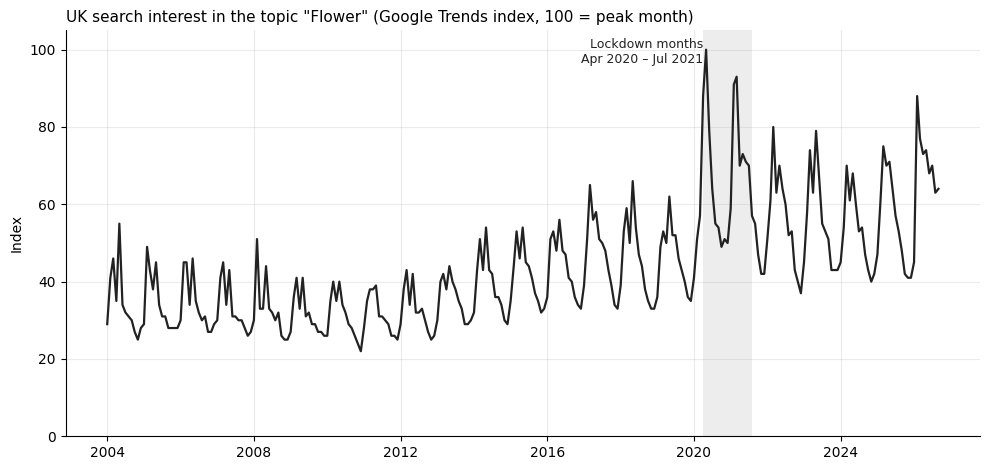

In [4]:
WINDOW = (pd.Timestamp('2020-04-01'), pd.Timestamp('2021-07-01'))
fig, ax = plt.subplots()
ax.axvspan(WINDOW[0], WINDOW[1] + pd.offsets.MonthEnd(0), color=GREY, alpha=0.15, lw=0)
ax.plot(y.index, y.values, color=INK, lw=1.6)
ax.text(WINDOW[0], 103, 'Lockdown months\nApr 2020 – Jul 2021', fontsize=9, color=INK, va='top', ha='right')
ax.set_title('UK search interest in the topic "Flower" (Google Trends index, 100 = peak month)', loc='left', fontsize=11)
ax.set_ylabel('Index'); ax.set_ylim(0, 105)
plt.tight_layout(); plt.savefig('figures/nb2_01_series.png', dpi=200); plt.show()

Three things a planner would note. The seasonal shape repeats every year: a February–March peak (Valentine's Day, then Mothering Sunday, the UK Mother's Day) and a second peak in May. Interest grew from about 2012 to 2017, then levelled off. And from April 2020 to July 2021 — the months of UK lockdown restrictions — interest jumped far above the pattern, then settled at a level higher than before 2020 but well below the lockdown peaks.

## 2. History cleansing: treating the lockdown months as a one-off

Planners routinely cleanse history before forecasting: a one-off event (a stock-out, a promotion, a pandemic) is replaced by what demand would have looked like without it, so the model does not learn it as a pattern. Here the window is **April 2020 to July 2021**, from the first full month of the first national lockdown to the month most legal restrictions ended in England. The window is a judgement, so every cleansed model is also run on the raw history.

The method is deliberately simple:
1. **Seasonal shape** — for each calendar month, its average deviation from its year's mean (on a log scale), using every complete year except 2020 and 2021.
2. **Level** — remove the seasonal shape, then replace the deseasonalised values inside the window with a straight line from the month before the window (March 2020) to the month after it (August 2021).
3. **Put the seasonal shape back.**

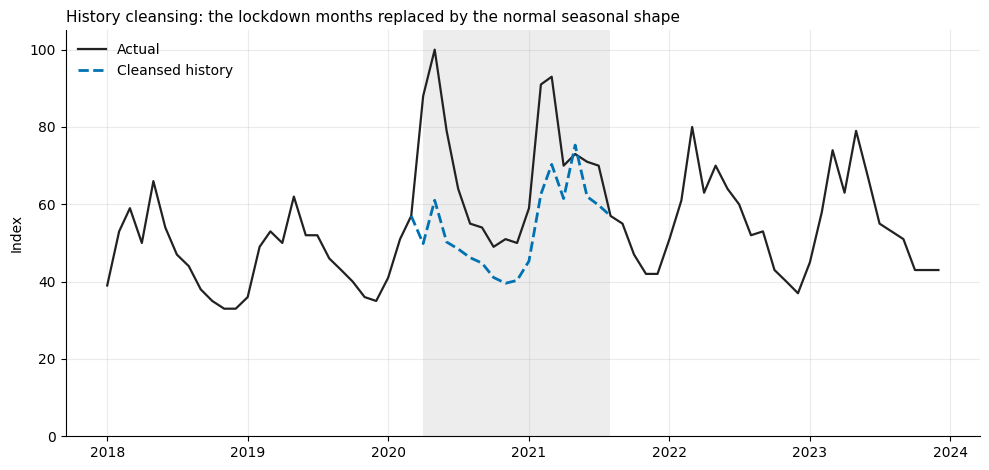

In [5]:
def seasonal_profile(s):
    """Average log deviation of each calendar month from its year's mean (complete years, 2020-21 excluded)."""
    ls = np.log(s)
    year = ls.index.year
    dev = ls - ls.groupby(year).transform('mean')
    keep = (ls.groupby(year).transform('size') == 12) & ~year.isin([2020, 2021])
    return dev[keep].groupby(dev[keep].index.month).mean()

def cleanse(s):
    """Replace the lockdown window with seasonal shape x a level interpolated across the window."""
    a, b = WINDOW
    left, right = a - pd.offsets.MonthBegin(1), b + pd.offsets.MonthBegin(1)
    if s.index[-1] < right:          # the month after the window must be known
        raise ValueError('cleansing needs data up to the month after the window')
    prof = seasonal_profile(s)
    ls = np.log(s)
    seasonal = ls.index.month.map(prof).values
    level = ls - seasonal
    inside = level.loc[a:b].index
    w = np.linspace(0, 1, len(inside) + 2)[1:-1]
    level.loc[inside] = level.loc[left] * (1 - w) + level.loc[right] * w
    return pd.Series(np.exp(level + seasonal), index=s.index, name=s.name)

y_clean = cleanse(y)
fig, ax = plt.subplots()
span = slice('2018-01-01', '2023-12-01')
ax.axvspan(WINDOW[0], WINDOW[1] + pd.offsets.MonthEnd(0), color=GREY, alpha=0.15, lw=0)
ax.plot(y.loc[span].index, y.loc[span].values, color=INK, lw=1.6, label='Actual')
ax.plot(y_clean.loc['2020-03-01':'2021-08-01'].index, y_clean.loc['2020-03-01':'2021-08-01'].values,
        color=BLUE, lw=2, ls='--', label='Cleansed history')
ax.legend(loc='upper left', frameon=False)
ax.set_title('History cleansing: the lockdown months replaced by the normal seasonal shape', loc='left', fontsize=11)
ax.set_ylabel('Index'); ax.set_ylim(0, 105)
plt.tight_layout(); plt.savefig('figures/nb2_02_cleansing.png', dpi=200); plt.show()

## 3. How the models are judged

**Like a planning cycle.** At the end of each month, every model is refitted on the data known at that point and forecasts the next 12 months. Each forecast is then compared with what actually happened.

- **Validation period** — forecasts made at the end of August 2021 to April 2022 (9 forecast dates). Every choice in this notebook — SARIMA orders, which model from each family to keep — is made here. (Cleansing needs the month after the window, so August 2021 is the first usable date.)
- **Test period** — forecasts made at the end of May 2023 to September 2025 (29 forecast dates), scored on June 2023 to September 2026. Nothing is tuned here; every model is reported.

**Measures.** Error = forecast − actual, so a positive error is an over-forecast.
- **WAPE** = Σ|error| ÷ Σactual: the size of the error, weighted by volume.
- **Bias** = Σerror ÷ Σactual: the direction. Positive means over-forecasting.
- **Months over-forecast**: the share of forecasts above the actual. Around 50% is unbiased.
- **Forecast value added (FVA)** = benchmark WAPE − model WAPE, in percentage points. Positive means the model beats "same month last year".

In [6]:
H = 12
VALID_ORIGINS = pd.date_range('2021-08-01', '2022-04-01', freq='MS')
TEST_ORIGINS = pd.date_range('2023-05-01', '2025-09-01', freq='MS')

def scores(d):
    e = d['forecast'] - d['actual']
    A = d['actual'].sum()
    return pd.Series({'forecasts': len(d), 'WAPE %': 100 * e.abs().sum() / A, 'bias %': 100 * e.sum() / A,
                      'months over-forecast %': 100 * (e > 0).mean()})

## 4. The candidates

| Family | Model | History | Why it is here |
|---|---|---|---|
| Benchmark | Seasonal naive: same month last year | raw | The bar every model must clear |
| Exponential smoothing | Holt-Winters, additive trend, multiplicative seasonality | raw | Notebook 1's baseline |
| | Holt-Winters, same spec | cleansed | Does cleansing help? |
| | Holt-Winters, **damped** trend | cleansed | A trend that flattens out instead of running on for ever |
| ARIMA | SARIMA (2,1,2)(3,1,1)12 | raw | The model notebook 1 chose |
| | SARIMA chosen by AIC, consistent differencing, log scale | raw and cleansed | Fixes notebook 1's selection |
| Prophet | Prophet with notebook 1's tuned settings and UK holidays | raw | Notebook 1's Prophet |
| | Same settings | cleansed | Does cleansing help? |
| Combination | Equal-weight average of the best model of each family **on validation** | — | Spreads the risk of picking the wrong model |

### Choosing the SARIMA orders properly

Notebook 1 searched with no seasonal differencing (D = 0) and then fitted a model with D = 1, so the model it used was never the one the search selected; AIC values are not comparable across different differencing anyway. Here the differencing is fixed first — d = 1 and D = 1, on the log of the series, because the seasonal swings grow with the level — and the search covers p, q ∈ {0, 1, 2} and P, Q ∈ {0, 1} on the data known at the first validation date. Rule: among models within 2 AIC points of the best, take the one with the fewest parameters.

In [7]:
z = np.log(cleanse(y.loc[:VALID_ORIGINS[0]]))
grid = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
        try:
            r = SARIMAX(z, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
            grid.append({'order': (p, 1, q), 'seasonal order': (P, 1, Q, 12), 'parameters': p + q + P + Q, 'AIC': r.aic})
        except Exception:
            pass
grid = pd.DataFrame(grid).sort_values('AIC').reset_index(drop=True)
near = grid[grid['AIC'] <= grid['AIC'].min() + 2]
choice = near.sort_values(['parameters', 'AIC']).iloc[0]
SARIMA_ORDER, SARIMA_SORDER = choice['order'], choice['seasonal order']
print(f"Chosen: SARIMA{SARIMA_ORDER}{SARIMA_SORDER[:3]}12 on log scale, AIC {choice['AIC']:.1f} "
      f"(best AIC {grid['AIC'].min():.1f}; {len(near)} models within 2 points)")
grid.head(6).round(1)

Chosen: SARIMA(0, 1, 1)(0, 1, 1)12 on log scale, AIC -506.3 (best AIC -506.4; 4 models within 2 points)


,order,seasonal order,parameters,AIC
0,"(0, 1, 1)","(1, 1, 1, 12)",3,-506.4
1,"(0, 1, 1)","(0, 1, 1, 12)",2,-506.3
2,"(1, 1, 1)","(1, 1, 1, 12)",4,-504.5
3,"(0, 1, 2)","(1, 1, 1, 12)",4,-504.5
4,"(1, 1, 1)","(0, 1, 1, 12)",3,-504.3
5,"(0, 1, 2)","(0, 1, 1, 12)",3,-504.3


In [8]:
FALLBACKS = []
NOT_CONVERGED = {}

def f_snaive(tr, trc):
    return np.tile(tr.iloc[-12:].values, 2)[:H]

def f_hw(t, damped=False):
    m = ExponentialSmoothing(t, trend='add', damped_trend=damped, seasonal='mul', seasonal_periods=12).fit()
    return m.forecast(H).values

def f_sarima(t, order, sorder, log):
    z = np.log(t) if log else t
    try:
        res = SARIMAX(z, order=order, seasonal_order=sorder).fit(disp=False)
    except Exception as e:          # numerical failure: record it and refit with a different optimiser
        FALLBACKS.append((f'SARIMA{order}{sorder[:3]}12', f'{t.index[-1]:%b %Y}', type(e).__name__))
        res = SARIMAX(z, order=order, seasonal_order=sorder).fit(disp=False, method='powell', maxiter=2000)
    f = res.get_forecast(H).predicted_mean.values
    return np.exp(f) if log else f

def f_prophet(t):
    d = pd.DataFrame({'ds': t.index + pd.offsets.MonthEnd(0), 'y': t.values})
    m = Prophet(changepoint_prior_scale=0.01, seasonality_prior_scale=0.1, holidays_prior_scale=0.01,
                seasonality_mode='multiplicative')          # notebook 1's tuned settings
    m.add_country_holidays(country_name='UK')
    m.fit(d)
    future = pd.DataFrame({'ds': pd.date_range(d['ds'].iloc[-1] + pd.offsets.MonthEnd(1), periods=H, freq='ME')})
    return m.predict(future)['yhat'].values

S = f'SARIMA{SARIMA_ORDER}{SARIMA_SORDER[:3]}12 log'
MODELS = {   # name: (family, function of raw and cleansed training data)
    'Seasonal naive (benchmark)':      ('Benchmark', f_snaive),
    'Holt-Winters (nb 1)':             ('Exponential smoothing', lambda tr, trc: f_hw(tr)),
    'Holt-Winters, cleansed':          ('Exponential smoothing', lambda tr, trc: f_hw(trc)),
    'Holt-Winters damped, cleansed':   ('Exponential smoothing', lambda tr, trc: f_hw(trc, damped=True)),
    'SARIMA(2,1,2)(3,1,1)12 (nb 1)':   ('ARIMA', lambda tr, trc: f_sarima(tr, (2, 1, 2), (3, 1, 1, 12), log=False)),
    S:                                 ('ARIMA', lambda tr, trc: f_sarima(tr, SARIMA_ORDER, SARIMA_SORDER, log=True)),
    S + ', cleansed':                  ('ARIMA', lambda tr, trc: f_sarima(trc, SARIMA_ORDER, SARIMA_SORDER, log=True)),
    'Prophet (nb 1 settings)':         ('Prophet', lambda tr, trc: f_prophet(tr)),
    'Prophet, cleansed':               ('Prophet', lambda tr, trc: f_prophet(trc)),
}

def backtest(origins):
    rows = []
    for o in origins:
        tr = y.loc[:o]
        trc = cleanse(tr)
        dates = pd.date_range(o + pd.offsets.MonthBegin(1), periods=H, freq='MS')
        for name, (family, fn) in MODELS.items():
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                fc = fn(tr, trc)
            if any('converge' in str(c.message).lower() for c in caught):
                NOT_CONVERGED[name] = NOT_CONVERGED.get(name, 0) + 1
            for h, (dt, f) in enumerate(zip(dates, fc), start=1):
                if dt in y.index:
                    rows.append({'model': name, 'family': family, 'origin': o, 'horizon': h, 'date': dt,
                                 'forecast': f, 'actual': y[dt]})
    return pd.DataFrame(rows)

t0 = time.time()
valid = backtest(VALID_ORIGINS)
test = backtest(TEST_ORIGINS)
n_fits = len(VALID_ORIGINS) + len(TEST_ORIGINS)
print(f'{len(MODELS)} models refitted at {n_fits} forecast dates in {time.time() - t0:.0f} s; per model, '
      f'{len(valid) // len(MODELS)} validation and {len(test) // len(MODELS)} test forecasts')
print('Fits that failed and needed the fallback optimiser:', FALLBACKS or 'none')
print(f'Fits ending with a convergence warning (out of {n_fits} per model):')
for name in MODELS:
    if name in NOT_CONVERGED:
        print(f'  {name}: {NOT_CONVERGED[name]}')

9 models refitted at 38 forecast dates in 297 s; per model, 108 validation and 348 test forecasts
Fits that failed and needed the fallback optimiser: [('SARIMA(2, 1, 2)(3, 1, 1)12', 'Oct 2021', 'LinAlgError')]
Fits ending with a convergence warning (out of 38 per model):
  Holt-Winters (nb 1): 3
  SARIMA(2,1,2)(3,1,1)12 (nb 1): 3


## 5. Validation: choosing what to trust

The rule is fixed before looking at the test: in each family, keep the model with the lowest validation WAPE; then average the family winners with equal weights.

In [9]:
v = valid.groupby('model').apply(scores)
v.insert(0, 'family', [MODELS[m][0] for m in v.index])
bench = v.loc['Seasonal naive (benchmark)', 'WAPE %']
v['FVA (points)'] = bench - v['WAPE %']
winners = v[v['family'] != 'Benchmark'].groupby('family')['WAPE %'].idxmin()
print('Family winners on validation:', '; '.join(f'{f}: {m}' for f, m in winners.items()))

def add_combination(df, members, name='Combination of family winners'):
    wide = df[df['model'].isin(members)].pivot_table(index=['origin', 'horizon', 'date', 'actual'],
                                                     columns='model', values='forecast')
    comb = wide[list(members)].mean(axis=1).rename('forecast').reset_index()
    comb['model'], comb['family'] = name, 'Combination'
    return pd.concat([df, comb[df.columns]], ignore_index=True)

COMB = 'Combination of family winners'
valid = add_combination(valid, winners.values)
v = valid.groupby('model').apply(scores)
v['FVA (points)'] = bench - v['WAPE %']
v.sort_values('WAPE %').round(1)

Family winners on validation: ARIMA: SARIMA(0, 1, 1)(0, 1, 1)12 log, cleansed; Exponential smoothing: Holt-Winters (nb 1); Prophet: Prophet, cleansed


,forecasts,WAPE %,bias %,months over-forecast %,FVA (points)
model,,,,,
"Prophet, cleansed",108.0,6.8,-2.2,45.4,6.1
Combination of family winners,108.0,6.8,4.0,71.3,6.1
Prophet (nb 1 settings),108.0,8.5,7.0,86.1,4.4
Holt-Winters (nb 1),108.0,8.6,6.3,79.6,4.3
"Holt-Winters damped, cleansed",108.0,9.1,7.7,88.0,3.8
"Holt-Winters, cleansed",108.0,9.3,7.9,88.0,3.7
"SARIMA(0, 1, 1)(0, 1, 1)12 log, cleansed",108.0,9.5,8.0,88.0,3.4
"SARIMA(0, 1, 1)(0, 1, 1)12 log",108.0,12.0,11.1,91.7,1.0
Seasonal naive (benchmark),108.0,12.9,12.9,98.1,0.0


## 6. Test: three years the choices never saw

In [10]:
test = add_combination(test, winners.values)
t = test.groupby('model').apply(scores)
t_bench = t.loc['Seasonal naive (benchmark)', 'WAPE %']
t['FVA (points)'] = t_bench - t['WAPE %']
t['validation WAPE %'] = v['WAPE %']
t = t.sort_values('WAPE %')
t.to_csv('forecast_results/nb2_test_scores.csv', float_format='%.2f')
t.round(1)

,forecasts,WAPE %,bias %,months over-forecast %,FVA (points),validation WAPE %
model,,,,,,
Holt-Winters (nb 1),348.0,6.5,-0.4,55.2,0.5,8.6
Combination of family winners,348.0,6.7,1.7,70.7,0.4,6.8
"Holt-Winters damped, cleansed",348.0,6.7,-0.3,56.9,0.3,9.1
"Holt-Winters, cleansed",348.0,6.7,0.3,59.5,0.3,9.3
"SARIMA(0, 1, 1)(0, 1, 1)12 log",348.0,6.8,-0.5,55.2,0.2,12.0
"SARIMA(0, 1, 1)(0, 1, 1)12 log, cleansed",348.0,7.0,-0.0,59.5,0.1,9.5
Seasonal naive (benchmark),348.0,7.0,-1.8,43.4,0.0,12.9
"Prophet, cleansed",348.0,8.7,5.3,86.2,-1.7,6.8
"SARIMA(2,1,2)(3,1,1)12 (nb 1)",348.0,10.5,0.2,52.6,-3.4,14.5


In [11]:
test['year'] = test['date'].dt.year
by_year = test.pivot_table(index='model', columns='year', values=['forecast', 'actual'], aggfunc='sum')
bias_year = 100 * (by_year['forecast'] - by_year['actual']) / by_year['actual']
bias_year.columns = [f'bias % {c}' + (' (Jan–Sep)' if c == 2026 else ' (Jun–Dec)' if c == 2023 else '') for c in bias_year.columns]
bias_year.loc[t.index].round(1)

,bias % 2023 (Jun–Dec),bias % 2024,bias % 2025,bias % 2026 (Jan–Sep)
model,,,,
Holt-Winters (nb 1),2.0,4.4,-1.6,-9.2
Combination of family winners,2.3,6.9,0.7,-8.2
"Holt-Winters damped, cleansed",0.7,5.4,-1.6,-10.2
"Holt-Winters, cleansed",1.0,5.9,-1.0,-9.7
"SARIMA(0, 1, 1)(0, 1, 1)12 log",-0.5,5.3,-1.8,-10.2
"SARIMA(0, 1, 1)(0, 1, 1)12 log, cleansed",1.7,6.0,-1.8,-9.9
Seasonal naive (benchmark),-3.7,5.9,-5.0,-10.7
"Prophet, cleansed",3.2,10.3,5.6,-5.7
"SARIMA(2,1,2)(3,1,1)12 (nb 1)",-2.1,5.5,-1.3,-7.0


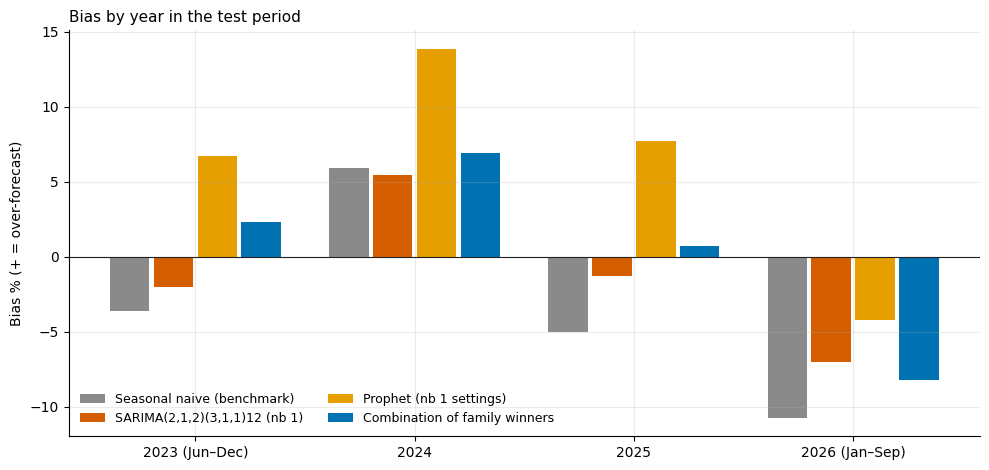

In [12]:
show = ['Seasonal naive (benchmark)', 'SARIMA(2,1,2)(3,1,1)12 (nb 1)', 'Prophet (nb 1 settings)', COMB]
colours = [GREY, VERMILION, ORANGE, BLUE]
years = sorted(test['year'].unique())
fig, ax = plt.subplots()
width = 0.2
for i, (m, c) in enumerate(zip(show, colours)):
    ax.bar(np.arange(len(years)) + (i - 1.5) * width, bias_year.loc[m].values, width=width * 0.9, color=c, label=m)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(np.arange(len(years)), ['2023 (Jun–Dec)', '2024', '2025', '2026 (Jan–Sep)'])
ax.set_ylabel('Bias % (+ = over-forecast)')
ax.set_title('Bias by year in the test period', loc='left', fontsize=11)
ax.legend(frameon=False, fontsize=9, ncol=2, loc='lower left')
plt.tight_layout(); plt.savefig('figures/nb2_03_bias_by_year.png', dpi=200); plt.show()

In [13]:
test['horizon band'] = pd.cut(test['horizon'], [0, 3, 6, 12], labels=['1–3 months', '4–6 months', '7–12 months'])
by_h = test.groupby(['model', 'horizon band'], observed=True).apply(
    lambda d: 100 * (d['forecast'] - d['actual']).abs().sum() / d['actual'].sum()).unstack()
by_h.loc[t.index].round(1)

horizon band,1–3 months,4–6 months,7–12 months
model,,,
Holt-Winters (nb 1),4.9,6.3,7.4
Combination of family winners,5.1,6.6,7.4
"Holt-Winters damped, cleansed",4.9,6.7,7.6
"Holt-Winters, cleansed",5.0,6.7,7.6
"SARIMA(0, 1, 1)(0, 1, 1)12 log",4.7,6.9,7.7
"SARIMA(0, 1, 1)(0, 1, 1)12 log, cleansed",5.2,6.9,7.8
Seasonal naive (benchmark),6.0,6.9,7.6
"Prophet, cleansed",7.6,8.8,9.2
"SARIMA(2,1,2)(3,1,1)12 (nb 1)",8.9,12.0,10.5


## 7. Reading the results

**Validation chose the combination's members.** In each family, the lowest validation WAPE won: Holt-Winters as in notebook 1 (8.6%), the airline SARIMA on cleansed history (9.5%), and Prophet on cleansed history (6.8%). Cleansing helped Prophet (8.5% → 6.8%) and SARIMA (12.0% → 9.5%) in validation; for Holt-Winters, the raw history did better.

**In the test, the combination came second of ten** (6.7%), behind plain Holt-Winters (6.5%). Picking Holt-Winters now would be hindsight: in validation it ranked fourth. The combination's job is to be reliably good, not the best in one period.

**Notebook 1's three models ranked first, ninth and tenth.** Its baseline, Holt-Winters, came first; the SARIMA it chose came ninth; its Prophet came tenth. The original SARIMA also failed to estimate once with the default optimiser (October 2021) and had to be refitted with another.

**Bias by year shows why one window misleads.** Every model over-forecast 2024 (bias +4.4% to +13.9%), and every model under-forecast January–September 2026 (−4.2% to −10.7%), when interest rose sharply: those nine months averaged 69, against 61 a year earlier. Over the whole test the two cancel out — a planner looking only at the average would miss both.

**Horizon matters.** For the combination, WAPE rises from 5.1% one to three months ahead to 7.4% at seven to twelve months; for the benchmark, from 6.0% to 7.6%. The models' advantage sits in the near months — the ones that drive orders.

## 8. The forward forecast, done properly

The combination's members are refitted on **all** the data, to September 2026, and forecast October 2026 to September 2027. The range is not a model assumption: it comes from the combination's own test errors. For each horizon, the 10th and 90th percentiles of actual ÷ forecast give an 80% range.

In [14]:
full_clean = cleanse(y)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    member_fc = pd.DataFrame({m: MODELS[m][1](y, full_clean) for m in winners.values},
                             index=pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq='MS'))
fc = member_fc.mean(axis=1).rename('forecast').to_frame()
ratio = test[test['model'] == COMB].assign(r=lambda d: d['actual'] / d['forecast']).groupby('horizon')['r']
fc['80% range low'] = fc['forecast'].values * ratio.quantile(0.10).values
fc['80% range high'] = fc['forecast'].values * ratio.quantile(0.90).values
fc['same month last year'] = y.loc[fc.index - pd.DateOffset(years=1)].values
fc.round(1).to_csv('forecast_results/nb2_forecast_2026-10_to_2027-09.csv')
out = fc.round(0).astype(int); out.index = out.index.strftime('%b %Y')
out.T

,Oct 2026,Nov 2026,Dec 2026,Jan 2027,Feb 2027,Mar 2027,Apr 2027,May 2027,Jun 2027,Jul 2027,Aug 2027,Sep 2027
forecast,52,49,49,55,77,86,76,86,74,69,64,61
80% range low,47,45,45,50,71,77,68,78,66,63,58,55
80% range high,54,51,50,57,80,90,79,92,79,76,73,70
same month last year,42,41,41,45,88,77,73,74,68,70,63,64


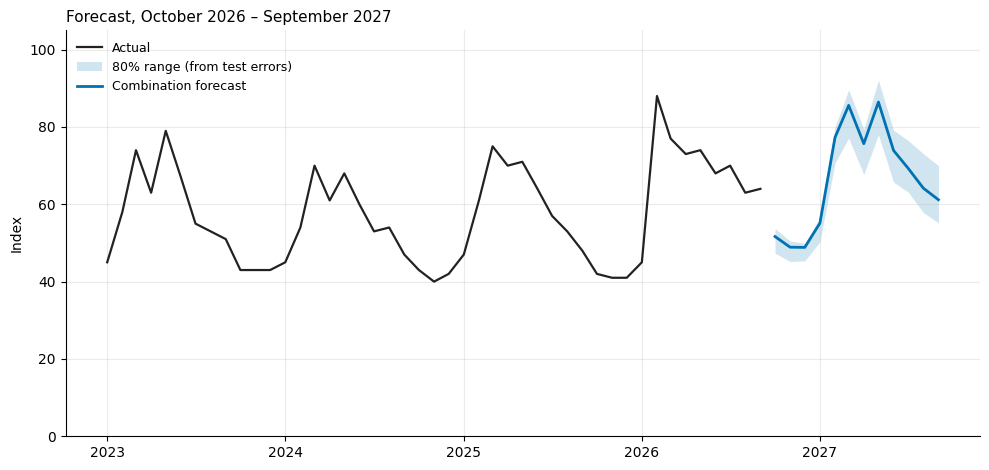

In [15]:
fig, ax = plt.subplots()
hist = y.loc['2023-01-01':]
ax.plot(hist.index, hist.values, color=INK, lw=1.6, label='Actual')
ax.fill_between(fc.index, fc['80% range low'], fc['80% range high'], color=BLUE, alpha=0.18, lw=0, label='80% range (from test errors)')
ax.plot(fc.index, fc['forecast'], color=BLUE, lw=2, label='Combination forecast')
ax.legend(frameon=False, loc='upper left', fontsize=9)
ax.set_title('Forecast, October 2026 – September 2027', loc='left', fontsize=11)
ax.set_ylabel('Index'); ax.set_ylim(0, 105)
plt.tight_layout(); plt.savefig('figures/nb2_04_forecast.png', dpi=200); plt.show()

## 9. Conclusions

1. **Judge a forecast against a benchmark, over many periods.** One 12-month window chose a model that ranked ninth of ten over three years.
2. **Measure bias separately from accuracy, and by period.** Prophet's +8% bias never appeared in notebook 1's MAE table; here it is the main finding. And bias flips with the market: over in 2024, under in 2026.
3. **Cleanse one-off events before forecasting.** Removing the lockdown months cut Prophet's bias and error, and helped SARIMA in validation. The window is a judgement, so it is tested both ways.
4. **Complexity has to earn its place.** In a steady market, "same month last year" was within half a point of the best model. The models added value when the level moved, and mostly in the first months of the horizon.
5. **Combine rather than bet.** The best single model changed between periods. An equal-weight combination of each family's validation winner was the only approach in the top two in both.

### Limitations
- Google Trends is an index of search interest, not sales. It is a demand signal, not demand.
- Each download is a fresh sample, so the index moves by a few points between downloads.
- The validation period (forecasts made August 2021 to April 2022) is short and comes straight after the lockdown, so it favours models that smooth through shocks. A longer validation period would make the family choices more reliable.
- The cleansing window is a judgement. It is tested both ways rather than assumed to help.